# CRNN–BiLSTM–CTC | Huấn luyện lại trên đúng split LPRNet v5

**Bản sửa theo Drive thực tế của người train CRNN**: ưu tiên
`MyDrive/Computer Vision/DoAnCuoiKy/Dataset/VNLP_detection.zip` (đường dẫn trong notebook CRNN đã gửi), và có dự phòng `MyDrive/TGMT/VNLP_detection.zip` (đường dẫn của thành viên LPRNet).

**Mục tiêu nghiên cứu:** tái dựng **chính xác** tập Train/Val/Test của LPRNet v5 bằng danh sách gốc, SHA-256, thuật toán nhóm và các file sửa nhãn của v5; huấn luyện lại CRNN từ đầu; đánh giá **greedy CTC** trên chính tập Test LPRNet v5. LPRNet được fine-tune từ pretrained, vì vậy kết quả chỉ là so sánh *hai hệ cấu hình*, không cô lập ảnh hưởng kiến trúc.

**Quan trọng:** file `vnlp_lpr_v5_shared_manifest.csv` từng xuất sai (26.792 mẫu `unreadable`) **KHÔNG** được sử dụng làm dữ liệu huấn luyện. Ta đọc trực tiếp ảnh từ ZIP gốc. Notebook không tự đoán nhãn, không tự loại test khó và không tự chia lại 80/10/10.

**Tài liệu nguồn đã dùng:** `CRNN_BiLSTM_CTC_VNLP_From_Scratch(1).ipynb` (kiến trúc CRNN) và `VN_ALPR_LPRNet_v5_TrainReview.ipynb` (phân chia dữ liệu, nhãn, tiền xử lý v5). Notebook này có thể chạy độc lập trong Google Colab sau khi file dữ liệu cần thiết nằm trong Drive của bạn.

### File cần thiết
1. `VNLP_detection.zip` — đã có trên Drive của bạn.
2. **`train_fixes.csv`** của lần train LPRNet v5, và `layout_corrections.csv` nếu thành viên có sử dụng — chép từ `TGMT/lprnet_v5/` sang Drive bạn, hoặc dùng trực tiếp nếu cùng Drive.
3. **`test_predictions.csv`** xuất từ LPRNet v5 — để xác minh 5.649 ảnh test, nhãn thật và so sánh paired; nếu chưa có vẫn có thể xây dữ liệu nhưng không được công bố kết quả so sánh.

Chỉ chỉnh **cell cấu hình** bên dưới. Nếu dữ liệu không khớp, notebook sẽ dừng trước khi train kèm hướng dẫn lỗi.

In [4]:
%pip -q install pandas numpy opencv-python-headless pillow matplotlib tqdm scipy scikit-learn

## 1. Kết nối Drive và cấu hình (CHỈ CẦN SỬA CELL NÀY)

`ZIP_PATH_OVERRIDE=''` để tự tìm đường dẫn gốc của bạn. Các file bổ trợ LPRNet sẽ được tìm trong các thư mục biết trước. **Đừng tải manifest lỗi vào đây.**

In [3]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

MYDRIVE = Path('/content/drive/MyDrive')
CRNN_PROJECT = MYDRIVE / 'Computer Vision/DoAnCuoiKy'

ZIP_PATH_OVERRIDE = ''  # VD: '/content/drive/MyDrive/.../VNLP_detection.zip' (để '' là tự tìm)
LPR_ARTIFACT_DIR_OVERRIDE = ''  # VD: '/content/drive/MyDrive/TGMT/lprnet_v5'
RUN_DIR = CRNN_PROJECT / 'CRNN_Retrain_LPRNet_v5_SameSplit'  # OUTPUT MỚI, không đè kết quả cũ

# Các tùy chọn chính
SEED = 42
EPOCHS = 85
BATCH_SIZE = 64              # CRNN có BiLSTM, có thể cần 32 nếu GPU thiếu RAM
NUM_WORKERS = 0             # 2 là mức an toàn cho Colab
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 15
USE_AUG = True               # Augmentation v5 chỉ áp dụng Train
USE_WEIGHTED_SAMPLER = True # lấy mẫu tăng xe máy/chữ hiếm theo trọng số LPRNet v5
RUN_SANITY = False           # khi muốn kiểm thử mô hình nhớ 32 ảnh, bật True
RUN_FINAL_TEST = True       # test chỉ sau khi train và chốt checkpoint
REQUIRE_LPR_TEST_CSV_BEFORE_TRAIN = True  # GIỮ TRUE để đảm bảo phép so sánh paired

# Giao thức đã cố định theo LPRNet v5
EXPECTED_TOTAL, EXPECTED_TRAIN, EXPECTED_VAL, EXPECTED_TEST = 37297, 26079, 5510, 5649
CRNN_W, CRNN_H = 256, 32
LPR_W, LPR_H = 94, 24
PAD_X, PAD_Y, SPLIT_OVERLAP, SPLIT_METHOD = .03, .06, .03, 'sloped'
EXIF_MODE, DROP_INVALID_LABELS = 'ignore', True
MOTO_WEIGHT, RARE_REF, RARE_MAX = 2.5, 1000, 3.0
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Thư mục lưu CRNN:', RUN_DIR)

Mounted at /content/drive
Thư mục lưu CRNN: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/CRNN_Retrain_LPRNet_v5_SameSplit


In [5]:
from pathlib import Path

p = Path('/content/drive/MyDrive/Computer Vision/DoAnCuoiKy/CRNN_Retrain_LPRNet_v5_SameSplit')

for name in ['crnn_last.pt', 'crnn_best.pt', 'history.csv']:
    f = p / name
    print(name, 'ĐÃ LƯU' if f.exists() else 'KHÔNG TÌM THẤY')

crnn_last.pt ĐÃ LƯU
crnn_best.pt ĐÃ LƯU
history.csv ĐÃ LƯU


In [6]:
import os, sys, io, csv, re, json, hashlib, random, time, math, shutil, zipfile, platform
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from scipy.stats import binomtest

cv2.setNumThreads(0)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Thiết bị:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else '')
print('Torch:', torch.__version__, '| OpenCV:', cv2.__version__, '| Python:', sys.version.split()[0])

def first_existing(candidates):
    return next((p for p in candidates if p.is_file()),None)

ZIP_PATH = Path(ZIP_PATH_OVERRIDE).expanduser() if ZIP_PATH_OVERRIDE else first_existing([
    CRNN_PROJECT/'Dataset/VNLP_detection.zip',  # CHÍNH XÁC đường dẫn từ notebook CRNN gốc
    MYDRIVE/'TGMT/VNLP_detection.zip',          # đường dẫn notebook LPRNet v5
    CRNN_PROJECT/'VNLP_detection.zip',
])
if ZIP_PATH is None or not ZIP_PATH.is_file():
    raise FileNotFoundError('Không tìm thấy VNLP_detection.zip. Kiểm tra MyDrive/Computer Vision/DoAnCuoiKy/Dataset; nếu khác, điền ZIP_PATH_OVERRIDE ở cell cấu hình.')

artifact_dirs=([Path(LPR_ARTIFACT_DIR_OVERRIDE)] if LPR_ARTIFACT_DIR_OVERRIDE else [])+[
    CRNN_PROJECT/'LPRNet_v5_shared',   # ưu tiên tài liệu LPR mà bạn đã chép vào project CRNN
    MYDRIVE/'TGMT/lprnet_v5',         # đúng thư mục notebook LPRNet của thành viên
    CRNN_PROJECT/'lprnet_v5',
    CRNN_PROJECT/'LPRNet_v5',
    CRNN_PROJECT/'Dataset/lprnet_v5',
]
# Không âm thầm ghép train_fixes của phiên bản A với test_predictions của phiên bản B.
LPR_SOURCE_DIR = next((p for p in artifact_dirs if (p/'train_fixes.csv').is_file() and (p/'test_predictions.csv').is_file()),None)
if LPR_SOURCE_DIR is None:
    LPR_SOURCE_DIR = next((p for p in artifact_dirs if (p/'train_fixes.csv').is_file()),None)
TRAIN_FIX_CSV = (LPR_SOURCE_DIR/'train_fixes.csv') if LPR_SOURCE_DIR is not None else None
LAYOUT_FIX_CSV = (LPR_SOURCE_DIR/'layout_corrections.csv') if LPR_SOURCE_DIR is not None and (LPR_SOURCE_DIR/'layout_corrections.csv').is_file() else None
LPR_TEST_PRED_CSV = (LPR_SOURCE_DIR/'test_predictions.csv') if LPR_SOURCE_DIR is not None and (LPR_SOURCE_DIR/'test_predictions.csv').is_file() else None
print('Thư mục file LPRNet:', LPR_SOURCE_DIR or 'CHƯA CÓ')
print('VNLP ZIP:',ZIP_PATH)
print('LPR train_fixes:',TRAIN_FIX_CSV or 'CHƯA CÓ')
print('LPR layout_corrections:',LAYOUT_FIX_CSV or 'Không có (dùng 21 sửa tay có sẵn của v5)')
print('LPR test_predictions:',LPR_TEST_PRED_CSV or 'CHƯA CÓ')

if TRAIN_FIX_CSV is None:
    raise FileNotFoundError('Thiếu train_fixes.csv của LPRNet v5. Hãy chép file từ Drive của thành viên LPRNet vào thư mục MyDrive/Computer Vision/DoAnCuoiKy/LPRNet_v5_shared/ rồi chạy lại. File này cần để tái lập đúng 26.079 train và nhãn đã sửa.')
if REQUIRE_LPR_TEST_CSV_BEFORE_TRAIN and LPR_TEST_PRED_CSV is None:
    raise FileNotFoundError('Thiếu test_predictions.csv của LPRNet v5. Chép file này cùng train_fixes.csv để kiểm tra chính xác 5.649 ảnh test TRƯỚC khi train; hoặc (không khuyến nghị) đặt REQUIRE_LPR_TEST_CSV_BEFORE_TRAIN=False.')

Thiết bị: cuda Tesla T4
Torch: 2.14.1+cu130 | OpenCV: 4.14.0 | Python: 3.13.16
Thư mục file LPRNet: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/LPRNet_v5_shared
VNLP ZIP: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/Dataset/VNLP_detection.zip
LPR train_fixes: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/LPRNet_v5_shared/train_fixes.csv
LPR layout_corrections: Không có (dùng 21 sửa tay có sẵn của v5)
LPR test_predictions: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/LPRNet_v5_shared/test_predictions.csv


## 2. Giải nén ZIP an toàn lên ổ Colab (không chép dữ liệu vào Drive)

Kiểm tra danh sách file VNLP, tránh dùng thư mục giải nén cũ của một ZIP khác. Hạn chế I/O trên Drive. Với 37 nghìn ảnh, bước giải nén và kiểm SHA có thể mất một lúc.

In [7]:
LOCAL_DIR = Path('/content/vnlp_crnn_lprv5')
MARKER = LOCAL_DIR/'.extract_identity.json'
identity={'zip_path':str(ZIP_PATH),'size':ZIP_PATH.stat().st_size,'mtime_ns':ZIP_PATH.stat().st_mtime_ns}
required_lists={'list_one_row.txt','list_two_row.txt','list_two_rows_label_xe_may.txt'}
if MARKER.is_file():
    try: old=json.loads(MARKER.read_text())
    except Exception: old={}
else: old={}
if old!=identity:
    if LOCAL_DIR.is_dir():shutil.rmtree(LOCAL_DIR)
    LOCAL_DIR.mkdir(parents=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        bad=z.testzip()
        if bad:raise RuntimeError(f'ZIP có tệp hỏng: {bad}')
        base=LOCAL_DIR.resolve()
        for item in tqdm(z.infolist(),desc='Giải nén VNLP'):
            if item.is_dir():continue
            dest=(LOCAL_DIR/item.filename).resolve()
            if dest!=base and base not in dest.parents:
                raise ValueError('ZIP chứa đường dẫn không an toàn: '+item.filename)
            dest.parent.mkdir(parents=True,exist_ok=True)
            with z.open(item) as src,open(dest,'wb') as dst:shutil.copyfileobj(src,dst)
    MARKER.write_text(json.dumps(identity))
else:print('Đã có dữ liệu từ đúng ZIP, tái sử dụng local cache.')

possible=[LOCAL_DIR/'detection',LOCAL_DIR]
possible.extend([p/'detection' for p in LOCAL_DIR.iterdir() if p.is_dir()])
TXT_DIR=next((p for p in possible if all((p/x).is_file() for x in required_lists)),None)
if TXT_DIR is None:
    raise RuntimeError('ZIP đã giải nén nhưng không tìm đủ 3 file list_*.txt; kiểm tra cấu trúc ZIP gốc.')
DATASET_DIR=TXT_DIR.parent if TXT_DIR.name=='detection' else TXT_DIR
print('DATASET_DIR:',DATASET_DIR,'| TXT_DIR:',TXT_DIR)

Giải nén VNLP:   0%|          | 0/37305 [00:00<?, ?it/s]

DATASET_DIR: /content/vnlp_crnn_lprv5 | TXT_DIR: /content/vnlp_crnn_lprv5/detection


## 3. Đọc nhãn VNLP và áp dụng cùng quy tắc LPRNet v5

Không lấy metadata `unreadable` từ manifest cũ. Dùng đúng quy tắc `O → 0`, `I → 1` và bộ ký tự 31 ký tự của LPRNet v5. `label_orig` dùng để tạo nhóm split và **không đổi** sau sửa nhãn.

In [8]:
CHARS=list('0123456789')+list('ABCDEFGHKLMNPSTUVXYZ')+['R']
assert len(CHARS)==31 and len(set(CHARS))==31
CHARSET=''.join(CHARS)
GROUPS=['1 dòng','2 dòng ô tô','xe máy']
LABEL_FIX={'O':'0','I':'1'}
VN_PLATE_RE=re.compile(r'^[0-9]{2}[A-Z]{1,2}[0-9]{4,6}$')

# Giống LPRNet v5: thứ tự 3 file list, nhãn và bbox từ tên file.
def read_list(name,group):
    samples=[]
    for line in (TXT_DIR/name).read_text(encoding='utf-8').splitlines():
        rel=line.strip().lstrip('/')
        if not rel:continue
        tokens=Path(rel).stem.split('_')
        if len(tokens)<8:raise ValueError(f'Tên VNLP thiếu tokens: {rel}')
        try:xy=tuple(map(int,tokens[4:8]))
        except ValueError:raise ValueError(f'BBox không hợp lệ: {rel}')
        if (DATASET_DIR/rel).is_file():img_path=DATASET_DIR/rel
        elif (DATASET_DIR/rel.replace('detection/','',1)).is_file():img_path=DATASET_DIR/rel.replace('detection/','',1)
        else:img_path=DATASET_DIR/rel # kiểm tra lỗi ở bước audit, không bỏ silently
        raw=tokens[3].upper()
        label=''.join(LABEL_FIX.get(c,c) for c in raw)
        image_id='detection/'+rel.removeprefix('detection/')
        samples.append(dict(img_path=str(img_path),image_id=image_id,label=label,label_orig=label,group=group,
                            is_two_rows=(tokens[2]=='0'),bbox=xy))
    return samples
all_samples=(read_list('list_one_row.txt','1 dòng')+read_list('list_two_row.txt','2 dòng ô tô')+
             read_list('list_two_rows_label_xe_may.txt','xe máy'))
print('Tổng mẫu đọc từ 3 danh sách VNLP:',len(all_samples))
print('Phân bố:',dict(Counter(s['group'] for s in all_samples)))
assert len(all_samples)==EXPECTED_TOTAL,f'ZIP VNLP không giống LPRNet v5: {len(all_samples)} != {EXPECTED_TOTAL}'
assert len(set(s['image_id'] for s in all_samples))==len(all_samples),'Một image_id xuất hiện nhiều lần!'

# Kiểm tra toàn bộ ảnh bằng pixel gốc, đúng cách inspect của LPRNet (không chỉnh EXIF).
def inspect_image(s):
    try:
        with open(s['img_path'],'rb') as f:data=f.read()
        sha=hashlib.sha256(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            w,h=im.size;orient=im.getexif().get(274,1)
    except Exception:
        return ('unreadable',0,0,1,None)
    if EXIF_MODE=='apply' and orient in (5,6,7,8):w,h=h,w
    xmin,ymin,xmax,ymax=s['bbox'];bw,bh=xmax-xmin,ymax-ymin
    if bw<8 or bh<4:return ('bad_bbox',w,h,orient,sha)
    tx,ty=.02*w,.02*h
    if xmin>=-tx and ymin>=-ty and xmax<=w+tx and ymax<=h+ty:
        mode='crop' if (bw>=.9*w and bh>=.9*h) else 'full'
    elif abs(w-bw)<=.25*bw and abs(h-bh)<=.25*bh:mode='crop'
    else:mode='bad_bbox'
    return (mode,w,h,orient,sha)
with ThreadPoolExecutor(max_workers=12) as pool:
    infos=list(tqdm(pool.map(inspect_image,all_samples),total=len(all_samples),desc='Kiểm tra dữ liệu và SHA256'))
for s,(mode,w,h,orient,sha) in zip(all_samples,infos):
    s.update(mode=mode,img_w=w,img_h=h,exif=orient,sha256=sha,layout_label=s['is_two_rows'])
print('Số ảnh đọc được:',sum(s['mode']!='unreadable' for s in all_samples))
print('Các mode:',Counter(s['mode'] for s in all_samples))
if sum(s['mode']=='unreadable' for s in all_samples)>0:
    raise RuntimeError('Phát hiện ảnh unreadable trong ZIP. DỪNG để kiểm tra ảnh/đường dẫn; không tái sử dụng manifest hỏng.')

Tổng mẫu đọc từ 3 danh sách VNLP: 37297
Phân bố: {'1 dòng': 19086, '2 dòng ô tô': 12618, 'xe máy': 5593}


Kiểm tra dữ liệu và SHA256:   0%|          | 0/37297 [00:00<?, ?it/s]

Số ảnh đọc được: 37297
Các mode: Counter({'full': 37297})


## 4. Sửa layout/nhãn đúng bản LPRNet v5 và tái tạo split

LPRNet v5 có **21 sửa layout** xác nhận bằng mắt và 1 ảnh `bad_bbox` được ghi trong notebook. File `layout_corrections.csv` bổ sung nếu có. `train_fixes.csv` bắt buộc để tái tạo lần train sau rà soát. Việc split đúng **70/15/15 theo nhóm biển gốc và ảnh SHA trùng** chứ không chia ngẫu nhiên từng ảnh.

In [9]:
KNOWN_LAYOUT_FIXES={
 **{p:False for p in [
 '3_210_0_36A05680_','6_1697_0_22A07557_','6_1703_0_28C02747_','6_2345_0_36A23747_',
 '6_2459_0_36A29035_','6_2477_0_36A30544_','6_2620_0_36A41816_','6_2764_0_36A42144_',
 '6_2943_0_36B01159_','6_3129_0_36C02489_','6_3625_0_36C29007_','6_4068_0_36C25362_',
 '7_2317_0_29M2972_','7_3031_0_36A27374_','7_3313_0_36A42616_','7_4295_0_36C17317_']},
 **{p:True for p in [
 '1_4015_1_36C25648_135_305_215_386.jpg','1_4120_1_36C27682_119_278_193_354.jpg',
 '4_3181_1_36C27959_242_251_375_332.jpg','7_2790_1_36A15181_178_220_407_344.jpg',
 '7_2817_1_36A16143_204_161_496_312.jpg']}
}
KNOWN_BAD_BBOX=['1_3823_1_36C09937_6_232_83_295.jpg']
by_name=defaultdict(list)
for s in all_samples:by_name[Path(s['img_path']).name].append(s)
names=sorted(by_name)

def unique_prefix(key):
    hits=[name for name in names if name.startswith(key)]
    if len(hits)!=1:raise ValueError(f'Sửa layout không khớp duy nhất: {key}, số ảnh = {len(hits)}')
    return hits[0]
layout_fixes=dict(KNOWN_LAYOUT_FIXES)
if LAYOUT_FIX_CSV is not None:
    with open(LAYOUT_FIX_CSV,encoding='utf-8-sig') as f:
        for row in csv.DictReader(f):
            layout=row['layout'].strip()
            assert layout in ('one_row','two_rows'),f'Layout không hợp lệ: {row}'
            layout_fixes[Path(row['file'].strip()).name]=layout=='two_rows'
for key,two in layout_fixes.items():
    for s in by_name[unique_prefix(key)]:s['is_two_rows']=two
for key in KNOWN_BAD_BBOX:
    for s in by_name[unique_prefix(key)]:s['mode']='bad_bbox'

fix_counts=Counter()
with open(TRAIN_FIX_CSV,encoding='utf-8-sig') as f:
    for row in csv.DictReader(f):
        action=(row.get('action') or '').strip().lower()
        if not action:continue
        assert action in ('drop','relabel','one_row','two_rows'),f'Action không hợp lệ: {row}'
        name=Path(row['file'].strip()).name
        if name not in by_name:raise ValueError(f'File trong train_fixes.csv không có trong ZIP: {name}')
        new_label=(row.get('new_label') or '').strip().upper()
        if action=='relabel' and not new_label:raise ValueError('Thiếu new_label cho '+name)
        for s in by_name[name]:
            fix_counts[action]+=1
            if action=='drop':s['manual_drop']=True
            elif action=='relabel':s['label']=new_label
            else:s['is_two_rows']=(action=='two_rows')
print('Sửa tay từ train_fixes:',dict(fix_counts))

def lpr_ctc_steps(w):
    w=w-4;w=(w-3)//2+1;w=(w-3)//2+1;return w-3

def min_ctc_steps(label):return len(label)+sum(a==b for a,b in zip(label,label[1:]))
def input_width(s):return 2*LPR_W if s['is_two_rows'] else LPR_W

def drop_reason(s):
    if s['mode'] in ('unreadable','bad_bbox'):return s['mode']
    if s.get('manual_drop'):return 'loại tay (train_fixes.csv)'
    if any(c not in CHARS for c in s['label']):return 'nhãn có ký tự ngoài bảng'
    if min_ctc_steps(s['label'])>lpr_ctc_steps(input_width(s)):return 'nhãn quá dài cho CTC'
    if DROP_INVALID_LABELS and not VN_PLATE_RE.match(s['label']):return 'nhãn sai định dạng VN'
    return 'OK'
for s in all_samples:
    s['drop']=drop_reason(s)
    s['input_ok']=s['mode'] in ('full','crop')

# Chính xác thuật toán phân nhóm và random permutation ở cell Bước 5 LPRNet v5.
parent=list(range(len(all_samples)))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]];i=parent[i]
    return i
first_seen={}
for i,s in enumerate(all_samples):
    for key in (('label',s['label_orig']),('sha256',s['sha256'])):
        if key[1] is None:continue
        if key in first_seen:parent[find(i)]=find(first_seen[key])
        else:first_seen[key]=i
components=defaultdict(list)
for i,s in enumerate(all_samples):components[find(i)].append(s)
comp_list=sorted(components.values(),key=lambda ss:min((s['label_orig'],s['img_path']) for s in ss))
order=np.random.RandomState(SEED).permutation(len(comp_list))
n_train=int(.70*len(comp_list));n_val=int(.15*len(comp_list))
parts={'train':order[:n_train],'val':order[n_train:n_train+n_val],'test':order[n_train+n_val:]}
split_all={key:[s for j in sorted(ids) for s in comp_list[j]] for key,ids in parts.items()}
for key,samples in split_all.items():
    for s in samples:s['split']=key
train_samples=[s for s in split_all['train'] if s['drop']=='OK']
val_samples=split_all['val']
test_samples=split_all['test']
print('Train/Val/Test (LPR v5):',len(train_samples),len(val_samples),len(test_samples))
if (len(train_samples),len(val_samples),len(test_samples)) != (EXPECTED_TRAIN,EXPECTED_VAL,EXPECTED_TEST):
    raise RuntimeError(f"""KHÔNG KHỚP LPRNet v5! Đang có {len(train_samples)}/{len(val_samples)}/{len(test_samples)}, cần {EXPECTED_TRAIN}/{EXPECTED_VAL}/{EXPECTED_TEST}.
Kiểm tra lại: VNLP_detection.zip, train_fixes.csv, layout_corrections.csv (nếu có), các sửa nhãn và phiên bản LPRNet v5. Không được huấn luyện/so sánh khi split lệch.""")
for k in ('label_orig','sha256'):
    sets={a:{s[k] for s in ss if s[k] is not None} for a,ss in split_all.items()}
    assert not(sets['train']&sets['val'] or sets['train']&sets['test'] or sets['val']&sets['test']),f'Rò rỉ {k}'
print('ĐÃ KHỚP số lượng mẫu và kiểm soát nhóm biển trùng!')

Sửa tay từ train_fixes: {'relabel': 112, 'drop': 32}
Train/Val/Test (LPR v5): 26079 5510 5649
ĐÃ KHỚP số lượng mẫu và kiểm soát nhóm biển trùng!


## 5. Xác minh từng ảnh của test LPRNet v5 (nếu có CSV)

Không chỉ đối chiếu số lượng. Phải đối chiếu **đúng ID từng ảnh và nhãn sau chỉnh sửa** với `test_predictions.csv` của LPRNet v5. Chỉ tiếp tục nếu khớp toàn bộ 5.649 mẫu; điều này tránh trường hợp hai split trùng số ảnh nhưng khác mẫu.

In [10]:
def id_from_any_path(value):
    norm=str(value).replace('\\','/').replace('\u005c','/')
    idx=norm.find('detection/')
    if idx<0:raise ValueError('Không suy được image_id từ: '+str(value))
    return norm[idx:]

def load_lpr_test():
    if LPR_TEST_PRED_CSV is None:
        print('CẢNH BÁO: Chưa có test_predictions.csv; không thể xác minh paired test hoặc McNemar.')
        return None
    frame=pd.read_csv(LPR_TEST_PRED_CSV,dtype=str,keep_default_na=False)
    if not {'img_path','gt','pred_greedy'}<=set(frame.columns):
        raise ValueError('test_predictions.csv thiếu cột img_path, gt, pred_greedy')
    frame['image_id']=frame['img_path'].map(id_from_any_path)
    if frame.image_id.duplicated().any():raise ValueError('test_predictions.csv có ID trùng')
    local=pd.DataFrame({'image_id':[s['image_id'] for s in test_samples],
                        'gt':[s['label'] for s in test_samples]})
    if set(local.image_id)!=set(frame.image_id):
        missing=set(local.image_id)-set(frame.image_id)
        extra=set(frame.image_id)-set(local.image_id)
        raise RuntimeError(f'SPLIT TEST KHÁC LPRNet v5! Thiếu {len(missing)}, dư {len(extra)}; ví dụ thiếu: {list(missing)[:3]}, dư: {list(extra)[:3]}')
    joint=local.merge(frame[['image_id','gt']],on='image_id',suffixes=('_crnn','_lpr'),validate='1:1')
    mismatch=joint[joint.gt_crnn!=joint.gt_lpr]
    if len(mismatch):
        raise RuntimeError(f'{len(mismatch)} nhãn GT không khớp LPRNet! Ví dụ:\n{mismatch.head(5).to_string(index=False)}\nCần đúng train_fixes.csv, bản dữ liệu và quy tắc nhãn LPRNet v5.')
    if len(frame)!=EXPECTED_TEST:raise RuntimeError(f'Test LPRNet CSV có {len(frame)} thay vì {EXPECTED_TEST}')
    print('ĐÃ XÁC MINH:',len(frame),'ảnh test + tất cả nhãn trùng LPRNet v5.')
    return frame
LPR_TEST_TABLE=load_lpr_test()
assert (LPR_TEST_TABLE is not None or not REQUIRE_LPR_TEST_CSV_BEFORE_TRAIN)

# Ghi một snapshot từ dữ liệu THẬT, không phải manifest unreadable cũ.
records=[]
for s in all_samples:
    records.append(dict(image_id=s['image_id'],label_orig=s['label_orig'],label=s['label'],split=s['split'],
                       layout=('two_rows' if s['is_two_rows'] else 'one_row'),group=s['group'],mode=s['mode'],
                       drop=s['drop'],input_ok=int(s['input_ok']),sha256=s['sha256'],
                       xmin=s['bbox'][0],ymin=s['bbox'][1],xmax=s['bbox'][2],ymax=s['bbox'][3]))
manifest=pd.DataFrame(records).sort_values('image_id').reset_index(drop=True)
MANIFEST_SHA=hashlib.sha256(manifest.to_csv(index=False).encode('utf-8')).hexdigest()
manifest.to_csv(RUN_DIR/'shared_manifest_verified.csv',index=False,encoding='utf-8-sig')
print('Manifest đúng đã lưu:',RUN_DIR/'shared_manifest_verified.csv')
print('Fingerprint:',MANIFEST_SHA)

ĐÃ XÁC MINH: 5649 ảnh test + tất cả nhãn trùng LPRNet v5.
Manifest đúng đã lưu: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/CRNN_Retrain_LPRNet_v5_SameSplit/shared_manifest_verified.csv
Fingerprint: 57c3897937a48c6cac219c761a2c01adaa5b40ab06f713a565bfa1c062575bfb


## 6. Tiền xử lý theo LPRNet v5 + chuẩn hóa chiều rộng CRNN

Nguồn hàm `crop_box`, `find_row_gap`, `split_two_rows`, augmentation giữ đúng code trong notebook LPRNet v5 đã tải lên. Ảnh hai dòng được xử lý thành hai hàng nối ngang **trước khi** đưa vào CRNN. **Khác biệt duy nhất ở giao diện ảnh**: LPRNet dùng `94×24`/`188×24`, còn CRNN dùng `256×32` có letterbox. Điều này phải ghi rõ khi so sánh.

In [11]:
# Hàm và biến bắt buộc của tiền xử lý LPRNet v5.
IMG_W,IMG_H=LPR_W,LPR_H
IMG_W2=2*IMG_W
SPLIT_METHOD='sloped'
IMREAD_FLAGS=cv2.IMREAD_COLOR|cv2.IMREAD_IGNORE_ORIENTATION

def read_image(path):return cv2.imread(str(path),IMREAD_FLAGS)

In [12]:
def resize_to(img, size):
    w, h = size
    interp = cv2.INTER_AREA if (img.shape[1] > w or img.shape[0] > h) else cv2.INTER_LINEAR
    return cv2.resize(img, (w, h), interpolation=interp)

def crop_box(s, img_w, img_h, is_train=False):
    xmin, ymin, xmax, ymax = s["bbox"]
    bw, bh = xmax - xmin, ymax - ymin
    if is_train:   # lệch bbox ngẫu nhiên: hơi hụt hoặc hơi rộng như bbox của YOLO
        l, r = np.random.uniform(-0.02, 0.08, 2) * bw
        t, b = np.random.uniform(-0.04, 0.14, 2) * bh
    else:
        l = r = PAD_X * bw
        t = b = PAD_Y * bh
    x0, y0 = max(0, int(round(xmin - l))), max(0, int(round(ymin - t)))
    x1, y1 = min(img_w, int(round(xmax + r))), min(img_h, int(round(ymax + b)))
    return x0, y0, x1, y1

def get_plate_crop(img, s, is_train=False):
    if s["mode"] == "crop":
        return img
    h, w = img.shape[:2]
    x0, y0, x1, y1 = crop_box(s, w, h, is_train)
    crop = img[y0:y1, x0:x1]
    return crop if crop.size > 0 else img

def find_row_gap(crop):
    """Tìm đường thẳng (có thể nghiêng) giữa 2 dòng chữ, cắt qua ít nét mực nhất.
    Trả về (y ở mép trái, y ở mép phải) theo pixel của crop và cờ tin cậy."""
    h, w = crop.shape[:2]
    if h < 12 or w < 12:
        return (h / 2, h / 2), False
    sh = 96
    sw = min(256, max(64, round(w * sh / h)))
    gray = cv2.cvtColor(cv2.resize(crop, (sw, sh), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    ink = (cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 7) > 0).astype(np.float32)
    xs = np.arange(round(0.12 * sw), round(0.88 * sw))               # bỏ viền / ốc vít hai bên khi chấm điểm
    cc, dd = np.meshgrid(np.arange(round(0.30 * sh), round(0.70 * sh) + 1),
                         np.linspace(-0.35 * sh, 0.35 * sh, 15), indexing="ij")
    cc, dd = cc.ravel().astype(np.float32), dd.ravel().astype(np.float32)
    ys = cc[:, None] + dd[:, None] * (xs[None, :] / max(1, sw - 1) - 0.5)

    def line_ink(y):
        return np.mean([ink[np.clip(np.rint(y + band).astype(int), 0, sh - 1), xs[None, :]].mean(axis=1)
                        for band in (-1, 0, 1)], axis=0)

    gap = line_ink(ys)
    score = gap + 0.04 * np.abs(cc / sh - 0.5) + 0.003 * np.abs(dd) / (0.35 * sh)   # hơi ưu tiên giữa và ít nghiêng
    b = int(np.argmin(score))
    above = max(float(line_ink(ys[b:b + 1] - o * sh)[0]) for o in (0.12, 0.18, 0.24))
    below = max(float(line_ink(ys[b:b + 1] + o * sh)[0]) for o in (0.12, 0.18, 0.24))
    ok = min(above, below) > 0.03 and gap[b] / max(1e-6, min(above, below)) < 0.65   # 2 phía đều có chữ, khe rõ
    y_left, y_right = (cc[b] - dd[b] / 2) * h / sh, (cc[b] + dd[b] / 2) * h / sh
    return (float(np.clip(y_left, 2, h - 2)), float(np.clip(y_right, 2, h - 2))), bool(ok)

def row_strip(crop, y_top, y_bot):
    """Nắn dải giữa 2 đường y_top, y_bot (mỗi cột một giá trị) thành dải thẳng, rồi resize về 94x24."""
    w = crop.shape[1]
    out_h = max(2, int(round(float(np.mean(y_bot - y_top)))))
    t = np.linspace(0, 1, out_h, dtype=np.float32)[:, None]
    map_y = (y_top[None, :] + t * (y_bot - y_top)[None, :]).astype(np.float32)
    map_x = np.tile(np.arange(w, dtype=np.float32), (out_h, 1))
    strip = cv2.remap(crop, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return resize_to(strip, (IMG_W, IMG_H))

def row_cut(crop):
    h, w = crop.shape[:2]
    if SPLIT_METHOD == "sloped":
        (y_left, y_right), ok = find_row_gap(crop)
    else:
        (y_left, y_right), ok = (h / 2, h / 2), True
    return np.linspace(y_left, y_right, w, dtype=np.float32), ok

def split_two_rows(crop, overlap=SPLIT_OVERLAP):
    # mỗi dòng được nắn thẳng và resize riêng về 94x24 như một biển 1 dòng, rồi ghép ngang -> 188x24
    h, w = crop.shape[:2]
    cut, _ = row_cut(crop)
    ov = overlap * h
    top = row_strip(crop, np.zeros(w, np.float32), np.minimum(cut + ov, h - 1))
    bot = row_strip(crop, np.maximum(cut - ov, 0), np.full(w, h - 1, np.float32))
    return np.concatenate((top, bot), axis=1)

def geo_aug(crop, two_rows):
    h, w = crop.shape[:2]
    if h < 4 or w < 4:
        return crop
    if np.random.rand() < 0.5:
        max_angle = 6.0 if two_rows else 3.5     # biển dài xoay ít hơn để không cắt mất góc
        M = cv2.getRotationMatrix2D((w / 2, h / 2), np.random.uniform(-max_angle, max_angle), np.random.uniform(0.95, 1.03))
        shear = np.random.uniform(-0.15, 0.15)
        M[0, 1] += shear
        M[0, 2] -= shear * h / 2
        crop = cv2.warpAffine(crop, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    if np.random.rand() < 0.3:
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        dst = src + (np.random.uniform(-0.04, 0.04, (4, 2)) * [w, h]).astype(np.float32)
        crop = cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src, dst), (w, h), borderMode=cv2.BORDER_REPLICATE)
    return crop

def degrade(x):
    """Đúng MỘT phép làm suy giảm chất lượng (không chồng nhiều phép như v2)."""
    h, w = x.shape[:2]
    kind = np.random.choice(["lowres", "blur", "motion", "jpeg"])
    if kind == "lowres":     # độ phân giải thấp (biển ở xa)
        f = np.random.uniform(0.6, 0.9)
        small = cv2.resize(x, (max(1, int(w * f)), max(1, int(h * f))), interpolation=cv2.INTER_AREA)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    if kind == "blur":
        return cv2.GaussianBlur(x, (3, 3), np.random.uniform(0.3, 0.8))
    if kind == "motion":     # nhòe chuyển động ngang
        k = np.zeros((3, 3), np.float32)
        k[1, :] = 1 / 3
        return cv2.filter2D(x, -1, k)
    ok, enc = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(np.random.uniform(40, 90))])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else x

def photo_aug(x0):
    x = x0.astype(np.float32)
    if np.random.rand() < 0.7:
        x = x * np.random.uniform(0.75, 1.25) + np.random.uniform(-25, 25)
    if np.random.rand() < 0.25:
        x = 255.0 * (np.clip(x, 0, 255) / 255.0) ** np.random.uniform(0.75, 1.35)
    if np.random.rand() < 0.1:
        x = np.repeat(x.mean(axis=2, keepdims=True), 3, axis=2)
    x = np.clip(x, 0, 255).astype(np.uint8)
    if np.random.rand() < 0.35:
        x = degrade(x)
    if np.random.rand() < 0.2:
        x = np.clip(x.astype(np.float32) + np.random.normal(0, np.random.uniform(2, 6), x.shape), 0, 255).astype(np.uint8)
    if x.std() < 0.5 * x0.std():   # mất quá nửa độ tương phản -> chữ khó đọc, dùng lại ảnh gốc
        return x0
    return x

def preprocess(img, s, is_train=False):
    """Ảnh BGR gốc + thông tin mẫu -> ảnh BGR uint8 24x94 (1 dòng) hoặc 24x188 (2 dòng) đưa vào LPRNet."""
    crop = get_plate_crop(img, s, is_train)
    if is_train:
        crop = geo_aug(crop, s["is_two_rows"])
    if s["is_two_rows"]:
        x = split_two_rows(crop)
    else:
        x = resize_to(crop, (IMG_W, IMG_H))
    if is_train:
        x = photo_aug(x)
    return x

def model_input(img, s, is_train=False):
    """Đầu vào mô hình cho một mẫu. Ảnh hỏng / bbox sai (chỉ có trong Val/Test) -> ảnh xám, dự đoán sẽ bị đặt rỗng."""
    if img is None or not s["input_ok"]:
        return np.full((IMG_H, input_width(s), 3), 127, np.uint8)
    return preprocess(img, s, is_train)

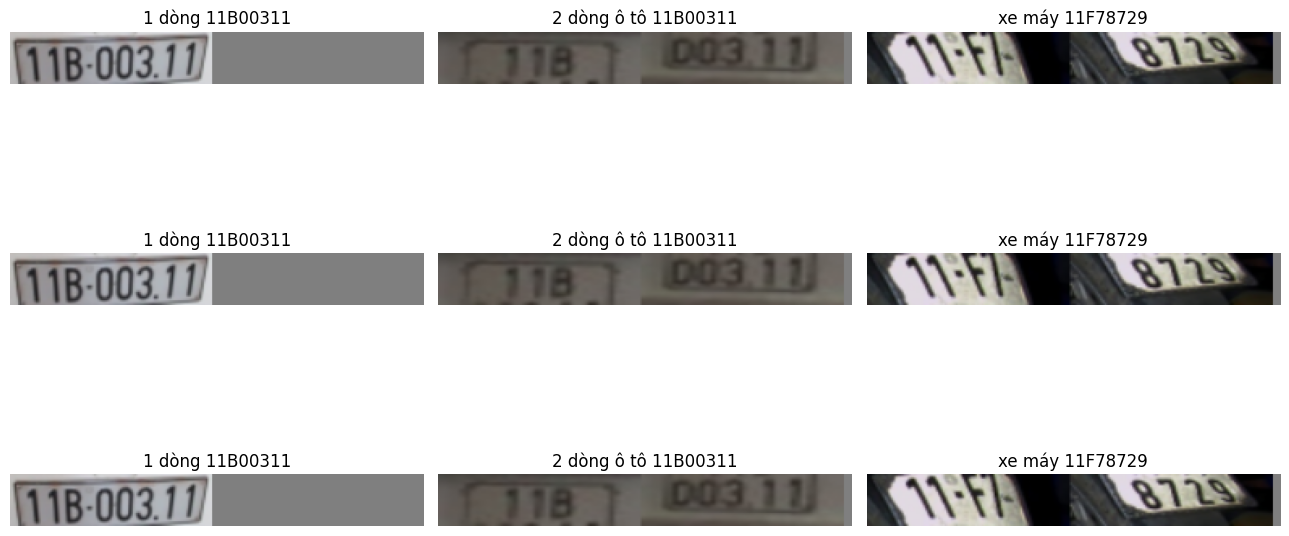

Đã kiểm tra trực quan mẫu từ cả 3 nhóm; nếu phát hiện crop/hàng bị cắt sai, dừng và kiểm tra dữ liệu.


In [13]:
def crnn_letterbox(image):
    if image is None or image.size==0:raise ValueError('Ảnh đầu vào rỗng')
    h,w=image.shape[:2]
    scale=min(CRNN_H/h,CRNN_W/w)
    neww,newh=max(1,int(round(w*scale))),max(1,int(round(h*scale)))
    small=cv2.resize(image,(neww,newh),interpolation=cv2.INTER_AREA if scale<1 else cv2.INTER_LINEAR)
    out=np.full((CRNN_H,CRNN_W,3),127,np.uint8)
    y=(CRNN_H-newh)//2
    out[y:y+newh,:neww]=small
    return out

def get_input(s,is_train=False):
    if not s['input_ok']:
        return np.full((CRNN_H,CRNN_W,3),127,np.uint8)
    img=read_image(s['img_path'])
    if img is None:
        raise RuntimeError('Dữ liệu đã pass audit nhưng không đọc được trong train: '+s['image_id'])
    # crop, tách/ghép hàng và augmentation giống LPRNet v5 (augmentation chỉ train)
    return crnn_letterbox(preprocess(img,s,is_train=is_train))

fig,axs=plt.subplots(3,3,figsize=(13,8))
for ax,(group,s) in zip(axs.flat,[(g,x) for g in GROUPS for x in [next(s for s in train_samples if s['group']==g)]]*3):
    ax.imshow(cv2.cvtColor(get_input(s),cv2.COLOR_BGR2RGB));ax.set_title(group+' '+s['label']);ax.axis('off')
plt.tight_layout();plt.show()
print('Đã kiểm tra trực quan mẫu từ cả 3 nhóm; nếu phát hiện crop/hàng bị cắt sai, dừng và kiểm tra dữ liệu.')

## 7. Dataset, weighted sampler và CRNN từ đầu

Cùng bộ nhãn 31 ký tự và GT LPRNet v5. Index blank của CRNN là 0 (LPRNet dùng blank cuối), điều đó **không làm thay đổi nội dung chuỗi**. Validation/Test luôn giữ cả mẫu bbox lỗi; dự đoán những mẫu đó được ép chuỗi rỗng để tính là sai.

In [14]:
CHAR2ID={ch:i+1 for i,ch in enumerate(CHARS)}
ID2CHAR={i+1:ch for i,ch in enumerate(CHARS)}
BLANK=0;NUM_CLASSES=len(CHARS)+1

class PlateDataset(Dataset):
    def __init__(self,samples,augment=False):self.samples=samples;self.augment=augment
    def __len__(self):return len(self.samples)
    def __getitem__(self,i):
        s=self.samples[i]
        x=get_input(s,is_train=(self.augment and USE_AUG))
        # output BGR theo LPRNet; CRNN không phụ thuộc trực tiếp thứ tự kênh nếu nhất quán train/test
        t=torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1))).float().div_(127.5).sub_(1.)
        return t,s

def collate(batch):
    imgs,samples=zip(*batch)
    return torch.stack(imgs),list(samples)

def worker_init(worker_id):
    ss=torch.initial_seed()%2**32
    np.random.seed(ss);random.seed(ss)

train_counts=Counter(c for s in train_samples for c in s['label'] if c.isalpha())
def sampler_weight(s):
    letters=[c for c in s['label'] if c.isalpha()]
    rare=max([np.sqrt(RARE_REF/max(1,train_counts[c])) for c in letters] or [1.0])
    return (MOTO_WEIGHT if s['group']=='xe máy' else 1.)*float(np.clip(rare,1.,RARE_MAX))
WEIGHTS=torch.tensor([sampler_weight(s) for s in train_samples],dtype=torch.double)

# Tạo lại loader từng epoch để chạy resume không phụ thuộc state của sampler trước đó.
def make_loader(split,epoch=0):
    samples={'train':train_samples,'val':val_samples,'test':test_samples}[split]
    train=split=='train'
    g=torch.Generator().manual_seed(SEED+epoch*1009+({'train':0,'val':1,'test':2}[split]))
    sampler=WeightedRandomSampler(WEIGHTS,len(train_samples),replacement=True,generator=g) if train and USE_WEIGHTED_SAMPLER else None
    return DataLoader(PlateDataset(samples,augment=train),batch_size=BATCH_SIZE,
       shuffle=(train and sampler is None),sampler=sampler,num_workers=NUM_WORKERS,
       pin_memory=(DEVICE.type=='cuda'),persistent_workers=False,
       collate_fn=collate,worker_init_fn=worker_init,generator=g)

class CRNN(nn.Module):
    """Kiến trúc CRNN gốc của nhóm: CNN -> 2-layer BiLSTM -> Linear -> CTC."""
    def __init__(self,nclass=NUM_CLASSES,hidden=256):
        super().__init__()
        def block(a,b):return [nn.Conv2d(a,b,3,padding=1,bias=False),nn.BatchNorm2d(b),nn.ReLU(inplace=True)]
        self.cnn=nn.Sequential(
            *block(3,64),nn.MaxPool2d(2,2),
            *block(64,128),nn.MaxPool2d(2,2),
            *block(128,256),*block(256,256),nn.MaxPool2d((2,1),(2,1)),
            *block(256,512),*block(512,512),nn.MaxPool2d((2,1),(2,1)),
            nn.Conv2d(512,512,(2,1),bias=False),nn.BatchNorm2d(512),nn.ReLU(inplace=True))
        self.rnn=nn.LSTM(512,hidden,num_layers=2,batch_first=True,bidirectional=True,dropout=.1)
        self.head=nn.Linear(hidden*2,nclass)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m,nn.Conv2d):nn.init.kaiming_normal_(m.weight,nonlinearity='relu')
        elif isinstance(m,nn.Linear):nn.init.xavier_uniform_(m.weight);nn.init.zeros_(m.bias)
    def forward(self,x):
        f=self.cnn(x)
        assert f.shape[2]==1, f'Feature height != 1: {f.shape}'
        seq=f.squeeze(2).transpose(1,2)
        y,_=self.rnn(seq)
        return self.head(y).transpose(0,1)

model=CRNN().to(DEVICE)
with torch.no_grad():probe=model(torch.zeros(2,3,CRNN_H,CRNN_W,device=DEVICE))
TIMESTEPS=int(probe.shape[0]);assert probe.shape==(64,2,NUM_CLASSES),tuple(probe.shape)
assert all(min_ctc_steps(s['label'])<=TIMESTEPS for s in train_samples)
print('Model parameters:',sum(p.numel() for p in model.parameters()))
print('CTC time steps:',TIMESTEPS,'| classes:',NUM_CLASSES)
del model,probe
if DEVICE.type=='cuda':torch.cuda.empty_cache()

Model parameters: 8198240
CTC time steps: 64 | classes: 32


## 8. Sanity check (tùy chọn, không dùng test)

Dùng tối đa 32 ảnh train và một model tạm; chỉ dùng để phát hiện bug crop/CTC, **không** chuyển trọng số sang lần train chính.

In [15]:
def greedy_decode(output):
    ids=output.detach().argmax(2).transpose(0,1).cpu().tolist()
    preds=[]
    for seq in ids:
        result=[];prev=None
        for idx in seq:
            if idx!=BLANK and idx!=prev:result.append(ID2CHAR[idx])
            prev=idx
        preds.append(''.join(result))
    return preds

def edit_distance(a,b):
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        cur=[i]
        for j,cb in enumerate(b,1):cur.append(min(cur[-1]+1,prev[j]+1,prev[j-1]+(ca!=cb)))
        prev=cur
    return prev[-1]

CTC=nn.CTCLoss(blank=BLANK,zero_infinity=False)
def loss_for_rows(logits,rows):
    # Val/Test có thể chứa nhãn không biểu diễn được, tính metric cho chúng nhưng KHÔNG ép loss giả.
    good=[i for i,s in enumerate(rows) if s['input_ok'] and s['label'] and
          all(c in CHAR2ID for c in s['label']) and min_ctc_steps(s['label'])<=logits.shape[0]]
    if not good:return None
    labels=[rows[i]['label'] for i in good]
    targets=torch.tensor([CHAR2ID[c] for t in labels for c in t],dtype=torch.long,device=DEVICE)
    lengths=torch.tensor([len(t) for t in labels],dtype=torch.long)
    input_lengths=torch.full((len(good),),logits.shape[0],dtype=torch.long)
    log_probs=logits[:,good,:].float().log_softmax(2)
    loss=CTC(log_probs,targets,input_lengths,lengths)
    if not torch.isfinite(loss):raise RuntimeError('CTC loss NaN/Inf, kiểm tra nhãn hoặc dữ liệu')
    return loss

if RUN_SANITY:
    one=[s for s in train_samples if not s['is_two_rows']][:32]
    xs=torch.stack([PlateDataset(one)[i][0] for i in range(len(one))]).to(DEVICE)
    small=CRNN().to(DEVICE).train()
    opt=torch.optim.AdamW(small.parameters(),lr=1e-3)
    for step in range(1,601):
        opt.zero_grad(set_to_none=True)
        out=small(xs);loss=loss_for_rows(out,one);loss.backward()
        nn.utils.clip_grad_norm_(small.parameters(),5);opt.step()
        if step%100==0:
            small.eval()
            with torch.no_grad():pred=greedy_decode(small(xs));acc=np.mean([p==s['label'] for p,s in zip(pred,one)])
            print('Sanity',step,'accuracy',round(acc,3),'loss',float(loss))
            small.train()
    assert acc>=.95,'CRNN không overfit được 32 ảnh; kiểm tra mã hoặc crop trước khi train'
    del small,opt
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
else:print('Bỏ qua sanity. Có thể bật RUN_SANITY=True khi cần kiểm tra dữ liệu.')

Bỏ qua sanity. Có thể bật RUN_SANITY=True khi cần kiểm tra dữ liệu.


In [16]:
import torch
from pathlib import Path

p = Path('/content/drive/MyDrive/Computer Vision/DoAnCuoiKy/CRNN_Retrain_LPRNet_v5_SameSplit')

ckpt = torch.load(
    p / 'crnn_last.pt',
    map_location='cpu',
    weights_only=False
)

print("Epoch đã lưu:", ckpt['epoch'])
print("Validation Accuracy tốt nhất:", ckpt['best_acc'])
print("Số epoch trong lịch sử:", len(ckpt['history']))

del ckpt

Epoch đã lưu: 82
Validation Accuracy tốt nhất: 0.9807622504537206
Số epoch trong lịch sử: 82


## 9. Huấn luyện từ đầu và lưu checkpoint an toàn

Dùng AdamW, clipping, scheduler ReduceLROnPlateau, lưu `best.pt`/`last.pt` và `history.csv`. Checkpoint kèm dấu vân tay dataset, tiền xử lý, charset và cấu hình; **không resume** nếu cấu hình khác. Dùng val để chọn epoch. Test chỉ chạy cuối cùng.

In [17]:
import copy

CONFIG_FINGERPRINT={
 'manifest':MANIFEST_SHA,'char_order':CHARSET,'batch_size':BATCH_SIZE,
 'seed':SEED,'lr':LR,'weight_decay':WEIGHT_DECAY,
 'w_h':(CRNN_W,CRNN_H),'lpr_crop':(LPR_W,LPR_H,PAD_X,PAD_Y,SPLIT_METHOD,SPLIT_OVERLAP),
 'weighted_sampler':USE_WEIGHTED_SAMPLER,'aug':USE_AUG,'model':'CRNN_cnn_bilstm2_256',
}
IDENTITY=hashlib.sha256(json.dumps(CONFIG_FINGERPRINT,sort_keys=True).encode()).hexdigest()
BEST=RUN_DIR/'crnn_best.pt';LAST=RUN_DIR/'crnn_last.pt';HIST=RUN_DIR/'history.csv'

def save_safe(obj,path):
    tmp=Path(str(path)+'.tmp')
    torch.save(obj,tmp);os.replace(tmp,path)

def make_epoch_seed(epoch):
    random.seed(SEED+epoch);np.random.seed((SEED+epoch)%(2**32));torch.manual_seed(SEED+epoch)
    if DEVICE.type=='cuda':torch.cuda.manual_seed_all(SEED+epoch)

def run_one_epoch(model,loader,optimizer=None):
    training=optimizer is not None
    model.train(training)
    losses=[];records=[]
    for images,rows in tqdm(loader,leave=False,desc='Train' if training else 'Val/Test'):
        images=images.to(DEVICE,non_blocking=True)
        with torch.set_grad_enabled(training):
            logits=model(images)
            loss=loss_for_rows(logits,rows)
            if training and loss is not None:
                optimizer.zero_grad(set_to_none=True)
                loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.)
                optimizer.step()
        if loss is not None:losses.append(float(loss.detach()))
        preds=greedy_decode(logits)
        for r,p in zip(rows,preds):
            if not r['input_ok']:p=''  # giống giao thức LPR, mẫu đầu vào lỗi tính sai
            records.append(dict(image_id=r['image_id'],gt=r['label'],pred_greedy=p,group=r['group'],
                                two_rows=int(r['is_two_rows']),input_ok=int(r['input_ok'])))
    frame=pd.DataFrame(records)
    assert len(frame)==len(loader.dataset)
    exact=float((frame['gt']==frame.pred_greedy).mean())
    cer=float(sum(edit_distance(g,p) for g,p in zip(frame['gt'],frame.pred_greedy))/max(1,frame['gt'].str.len().sum()))
    return {'loss':float(np.mean(losses)) if losses else float('nan'),'accuracy':exact,'cer':cer,'records':frame}

make_epoch_seed(0)
model=CRNN().to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=.5,patience=4,min_lr=1e-6)
start_epoch=1;best_acc=-1.;best_cer=float('inf');stale=0;history=[]
if LAST.is_file():
    state=torch.load(LAST,map_location='cpu',weights_only=False)
    if state['identity']!=IDENTITY:raise RuntimeError('Checkpoint đã có thuộc dữ liệu/cấu hình khác. Đổi RUN_DIR hoặc xử lý rõ checkpoint cũ; không tự overwrite.')
    model.load_state_dict(state['model']);optimizer.load_state_dict(state['optimizer'])
    scheduler.load_state_dict(state['scheduler'])
    start_epoch=state['epoch']+1;best_acc=state['best_acc'];best_cer=state['best_cer'];stale=state['stale'];history=state['history']
    print('Resume hợp lệ sau epoch',state['epoch'])
else:print('Huấn luyện CRNN từ trọng số khởi tạo ngẫu nhiên (from scratch).')

for epoch in (range(start_epoch,EPOCHS+1) if stale < PATIENCE else []):
    make_epoch_seed(epoch)
    a=run_one_epoch(model,make_loader('train',epoch),optimizer)
    b=run_one_epoch(model,make_loader('val',epoch))
    scheduler.step(b['accuracy'])
    better=(b['accuracy']>best_acc+1e-12 or (abs(b['accuracy']-best_acc)<=1e-12 and b['cer']<best_cer))
    if better:best_acc=b['accuracy'];best_cer=b['cer'];stale=0
    else:stale+=1
    row={'epoch':epoch,'train_loss':a['loss'],'train_acc':a['accuracy'],'train_cer':a['cer'],
         'val_loss':b['loss'],'val_acc':b['accuracy'],'val_cer':b['cer'],
         'lr':optimizer.param_groups[0]['lr']}
    history.append(row)
    payload={'identity':IDENTITY,'epoch':epoch,'model':model.state_dict(),'optimizer':optimizer.state_dict(),
             'scheduler':scheduler.state_dict(),'best_acc':best_acc,'best_cer':best_cer,'stale':stale,'history':history}
    save_safe(payload,LAST)
    if better:save_safe(payload,BEST)
    pd.DataFrame(history).to_csv(HIST,index=False)
    print(f"{epoch:03d}/{EPOCHS} train={a['accuracy']:.4f} val={b['accuracy']:.4f} CER={b['cer']:.4f} best={best_acc:.4f} lr={row['lr']:.2g} {'*' if better else ''}")
    if stale>=PATIENCE:
        print('Early stopping theo Val ở epoch',epoch);break
print('Checkpoint tốt nhất:',BEST)

Resume hợp lệ sau epoch 82


Train:   0%|          | 0/408 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/87 [00:00<?, ?it/s]

083/85 train=0.9908 val=0.9808 CER=0.0036 best=0.9808 lr=3.1e-05 


Train:   0%|          | 0/408 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/87 [00:00<?, ?it/s]

084/85 train=0.9928 val=0.9806 CER=0.0036 best=0.9808 lr=3.1e-05 


Train:   0%|          | 0/408 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/87 [00:00<?, ?it/s]

085/85 train=0.9910 val=0.9811 CER=0.0035 best=0.9811 lr=3.1e-05 *
Checkpoint tốt nhất: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/CRNN_Retrain_LPRNet_v5_SameSplit/crnn_best.pt


## 10. Vẽ biểu đồ và kiểm thử CRNN một lần trên cùng 5.649 ảnh test

Sử dụng `crnn_best.pt`, không dùng `last.pt`. Test không được sử dụng để chọn siêu tham số. Kết quả xuất CSV từng ảnh và bảng theo nhóm.

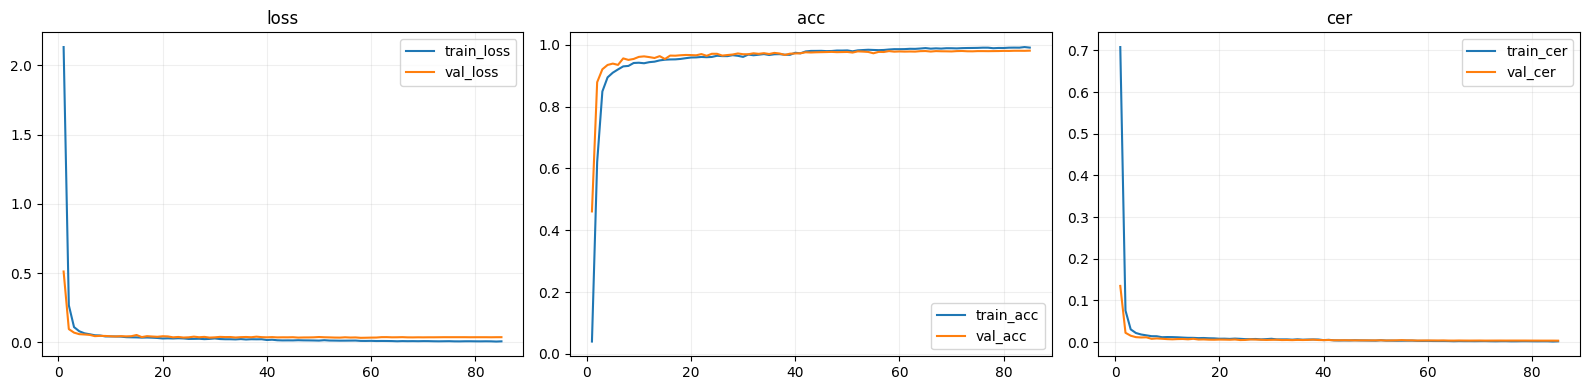

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]

TEST CRNN: {'dataset': '/content/drive/MyDrive/Computer Vision/DoAnCuoiKy/Dataset/VNLP_detection.zip', 'data_identity': '57c3897937a48c6cac219c761a2c01adaa5b40ab06f713a565bfa1c062575bfb', 'model': 'CRNN-BiLSTM-CTC from scratch', 'test_samples': 5649, 'epoch_best': 85, 'greedy_accuracy': 0.9785802796955213, 'greedy_cer': 0.004669587925463639, 'test_loss': 0.04715422552082723}


,group,samples,accuracy,cer
0,1 dòng,2905,0.986919,0.003589
1,2 dòng ô tô,1918,0.985923,0.002448
2,xe máy,826,0.932203,0.012741


In [18]:
hist=pd.read_csv(HIST)
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,(x,y) in zip(ax,[('train_loss','val_loss'),('train_acc','val_acc'),('train_cer','val_cer')]):
    a.plot(hist.epoch,hist[x],label=x);a.plot(hist.epoch,hist[y],label=y);a.legend();a.grid(alpha=.2);a.set_title(x.removeprefix('train_'))
plt.tight_layout();plt.savefig(RUN_DIR/'training_curves.png',dpi=170);plt.show()

if RUN_FINAL_TEST:
    ck=torch.load(BEST,map_location='cpu',weights_only=False)
    assert ck['identity']==IDENTITY
    test_model=CRNN().to(DEVICE)
    test_model.load_state_dict(ck['model'])
    test_result=run_one_epoch(test_model,make_loader('test',0))
    pred=test_result.pop('records')
    assert len(pred)==EXPECTED_TEST and pred.image_id.is_unique
    pred.to_csv(RUN_DIR/'crnn_test_predictions.csv',index=False,encoding='utf-8-sig')
    report={'dataset':str(ZIP_PATH),'data_identity':MANIFEST_SHA,'model':'CRNN-BiLSTM-CTC from scratch',
            'test_samples':len(pred),'epoch_best':ck['epoch'], 'greedy_accuracy':test_result['accuracy'],
            'greedy_cer':test_result['cer'],'test_loss':test_result['loss']}
    by_group=[]
    for grp,g in pred.groupby('group'):
        by_group.append(dict(group=grp,samples=len(g),accuracy=float((g['gt']==g.pred_greedy).mean()),
                             cer=float(sum(edit_distance(x,y) for x,y in zip(g['gt'],g.pred_greedy))/max(1,g['gt'].str.len().sum()))))
    pd.DataFrame(by_group).to_csv(RUN_DIR/'test_by_group.csv',index=False)
    (RUN_DIR/'crnn_test_metrics.json').write_text(json.dumps(report,ensure_ascii=False,indent=2))
    print('TEST CRNN:',report);display(pd.DataFrame(by_group))
else:print('Test chưa bật. Đặt RUN_FINAL_TEST=True sau khi khóa cấu hình.')

## 11. So sánh CRNN và LPRNet v5 trên từng ảnh (McNemar)

Chỉ chạy nếu có CSV của LPRNet v5. Kiểm tra **tập ảnh, nhãn thật, số lượng** rồi ghép 1–1. Chỉ số chính: greedy CRNN vs greedy LPRNet. Giải mã ràng buộc của LPRNet báo cáo bổ sung, không so trực tiếp như hai kiến trúc OCR thuần.

In [19]:
CRNN_PRED_PATH=RUN_DIR/'crnn_test_predictions.csv'
if not CRNN_PRED_PATH.is_file() or LPR_TEST_TABLE is None:
    print('Chưa đủ output CRNN / LPRNet để làm paired comparison.')
else:
    cr=pd.read_csv(CRNN_PRED_PATH,dtype=str,keep_default_na=False)
    lp=LPR_TEST_TABLE.copy()
    a=cr.merge(lp[['image_id','gt','pred_greedy']+[c for c in ['pred_constrained'] if c in lp.columns]],
               on='image_id',suffixes=('_crnn','_lpr'),validate='1:1')
    assert len(a)==EXPECTED_TEST and (a.gt_crnn==a.gt_lpr).all(),'ID/GT không khớp khi ghép!'
    a['correct_crnn']=(a.gt_crnn==a.pred_greedy_crnn)
    a['correct_lpr']=(a.gt_lpr==a.pred_greedy_lpr)
    only_crnn=int((a.correct_crnn&~a.correct_lpr).sum())
    only_lpr=int((~a.correct_crnn&a.correct_lpr).sum())
    both=int((a.correct_crnn&a.correct_lpr).sum())
    neither=int((~a.correct_crnn&~a.correct_lpr).sum())
    pval=float(binomtest(min(only_crnn,only_lpr),only_crnn+only_lpr,.5).pvalue) if only_crnn+only_lpr else 1.
    summary={'n':len(a),'crnn_greedy_accuracy':float(a.correct_crnn.mean()),
             'lpr_greedy_accuracy':float(a.correct_lpr.mean()),'both_correct':both,
             'crnn_only_correct':only_crnn,'lpr_only_correct':only_lpr,
             'both_wrong':neither,'mcnemar_exact_two_sided_p':pval}
    if 'pred_constrained' in a:
        summary['lpr_constrained_accuracy']=float((a.gt_lpr==a.pred_constrained).mean())
    a.to_csv(RUN_DIR/'paired_crnn_lprnet_v5_test.csv',index=False,encoding='utf-8-sig')
    (RUN_DIR/'paired_comparison.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
    print('SO SÁNH PAIRED:',json.dumps(summary,ensure_ascii=False,indent=2))
    print('Chú ý: pretrained vs scratch, tiền xử lý/siêu tham số khác nhau; không được kết luận thuần túy do kiến trúc.')

SO SÁNH PAIRED: {
  "n": 5649,
  "crnn_greedy_accuracy": 0.9785802796955213,
  "lpr_greedy_accuracy": 0.934855726677288,
  "both_correct": 5267,
  "crnn_only_correct": 261,
  "lpr_only_correct": 14,
  "both_wrong": 107,
  "mcnemar_exact_two_sided_p": 4.033242589996524e-60,
  "lpr_constrained_accuracy": 0.9470702779252965
}
Chú ý: pretrained vs scratch, tiền xử lý/siêu tham số khác nhau; không được kết luận thuần túy do kiến trúc.


## 12. Hồ sơ kết quả đưa vào báo cáo

File trong `RUN_DIR`:

- `shared_manifest_verified.csv`: manifest được **xây lại từ ZIP**, có split/nhãn/bbox và SHA đã kiểm.
- `crnn_best.pt`, `crnn_last.pt`, `history.csv`, `training_curves.png`.
- `crnn_test_predictions.csv`, `crnn_test_metrics.json`, `test_by_group.csv`.
- `paired_crnn_lprnet_v5_test.csv`, `paired_comparison.json` (nếu có file test prediction của LPRNet).

**Cách viết khoa học:** Nói rõ CRNN train from scratch, LPRNet fine-tune từ trọng số tác giả; dùng đúng tập test 5.649 ảnh, chuẩn hóa 31 ký tự chung, crop/tách–ghép dùng chung quy trình v5 nhưng hai mô hình có kích thước đầu vào khác nhau. Không dùng test để chọn mô hình hoặc điều chỉnh nhãn sau khi xem dự đoán. Nếu cần thay đổi dữ liệu/giao thức, tạo `RUN_DIR` mới và ghi lại thành một thí nghiệm khác.

**Lưu ý về bản v5:** Các thao tác sửa nhãn và loại ảnh phải được kiểm tra lịch sử (có/không sử dụng dự đoán từ test) để đánh giá nguy cơ test contamination. Test có ảnh khó không tự loại bỏ. Khi báo cáo so sánh, đưa bảng đúng/sai ghép cặp và McNemar, đồng thời mô tả các giới hạn do initialization và augmentation khác nhau.